In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()
tables_ready = True

# Transition and coherent transition radiation

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/10-transition-radiation.py)

An electron crossing a thin film radiates transition radiation (TR) at both
faces. Show that the two contributions interfere with a fringe period set by
film thickness, then let a short bunch radiate coherently (CTR) and compare
the enhancement with the ideal bunch form factor. The beam is **30 keV**,
the film is silicon, and observation is at **150°**.

In [ ]:
assert tables_ready
from scipy.constants import physical_constants

from pyrite import simulate
from pyrite.beams import Beam, LongitudinalDistribution, TransverseSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector, EnergyBins
from pyrite.geometry import Footprint, Slab
from pyrite.units import ureg

beam_keV, observation_deg = 30.0, 150.0
bunch_charge_pc = 1e-4  # about 624 physical electrons per bunch
photon_grid_eV = np.arange(200.0, 600.5, 1.0)  # 1 eV resolves the thinnest fringes
numerics = Numerics(
    sampling=FixedSampling(
        cxr_electrons=64, brem_electrons=512
    ),  # TR uses the continuum population
    cxr_reflections=CxrReflections(n_families=1),
    energy_model="midpoint",
    seed=1,
    energy_bins=(
        EnergyBins()
        .with_cxr_energies(photon_grid_eV * ureg.eV)
        .with_brem_energies(np.array([200.0, 600.0]) * ureg.eV)
    ),
)


def transition(thickness_nm, *, coherence="history", rms_as=1.0):
    """TR spectrum per incident electron for one film and bunch duration."""
    result = simulate(
        Beam(
            kinetic_energy=beam_keV * ureg.keV,
            transverse=TransverseSpot(fwhm_x=1 * ureg.nm),
            longitudinal=LongitudinalDistribution(
                "gaussian", rms_duration=rms_as * ureg.attosecond
            ),
            bunch_charge=bunch_charge_pc * ureg.pC,
            repetition_rate=5 * ureg.kHz,
        ),
        Slab(
            "silicon",
            thickness=thickness_nm * ureg.nm,
            tilt=5 * ureg.degree,
            footprint=Footprint(width=5 * ureg.mm, height=5 * ureg.mm),
        ),
        Detector(observation_angle=observation_deg * ureg.degree),
        physics=Physics(
            transition_radiation=coherence,
            radiative_model="uncoupled",
            bremsstrahlung_model="eedl",
        ),
        numerics=numerics,
    )
    return result.transition


electron_rest_keV = physical_constants["electron mass energy equivalent in MeV"][0] * 1_000
hc_eV_nm = (
    physical_constants["Planck constant in eV/Hz"][0]
    * physical_constants["speed of light in vacuum"][0]
    * 1e9
)
gamma = 1 + beam_keV / electron_rest_keV
beta = np.sqrt(1 - gamma**-2)

In [ ]:
assert tables_ready
film_nm = (10.0, 40.0)
films = {_t: transition(_t) for _t in film_nm}
# Same 20 nm film and seed: incoherent histories versus two bunch durations.
tr_20 = transition(20.0)
durations_as = (1.0, 2.0)
ctr_20 = {_s: transition(20.0, coherence="bunch", rms_as=_s) for _s in durations_as}

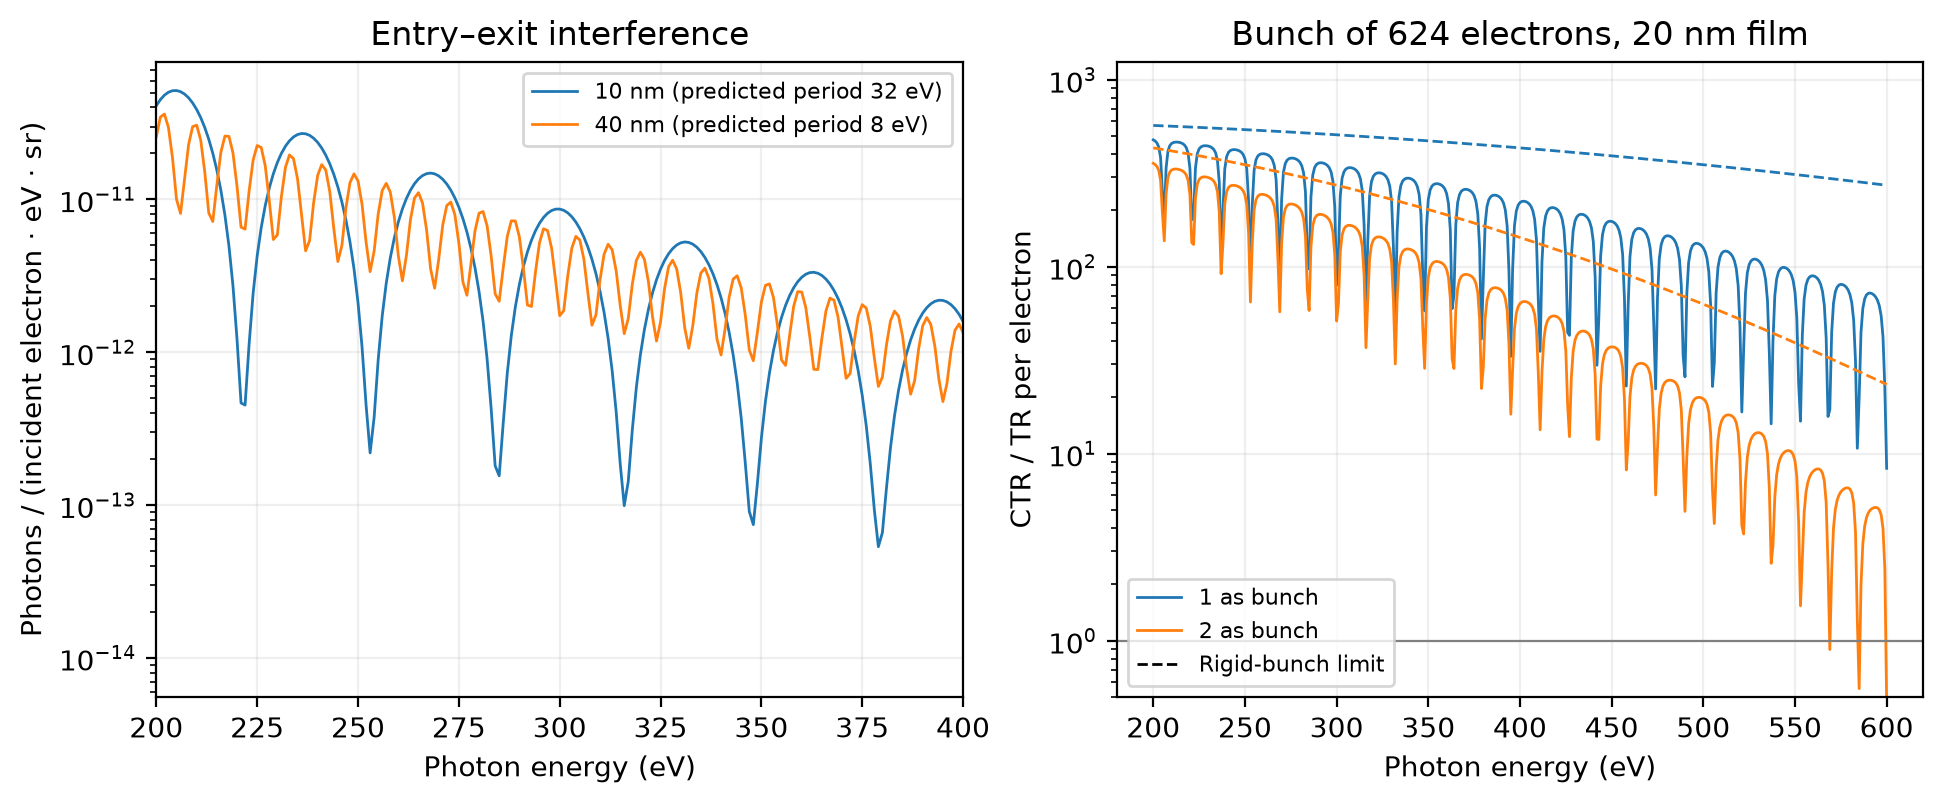

In [ ]:
from scipy.constants import elementary_charge, hbar

fig_tr, (_film_ax, _ctr_ax) = plt.subplots(1, 2, figsize=(9.6, 3.9), layout="constrained")
# Entry and exit fields differ in phase by omega * L * (1/beta - cos theta) / c.
_phase_factor = 1 / beta - np.cos(np.radians(observation_deg))
for _t in film_nm:
    _spectrum = films[_t]
    _period = hc_eV_nm / (_t * _phase_factor)
    _film_ax.plot(
        _spectrum.photon_energy_eV,
        _spectrum.density,
        lw=1,
        label=f"{_t:g} nm (predicted period {_period:.0f} eV)",
    )
_film_ax.set(xlim=(200, 400), yscale="log", title="Entry–exit interference")

_energy = tr_20.photon_energy_eV
_electrons = bunch_charge_pc * 1e-12 / elementary_charge
for _i, _sigma in enumerate(durations_as):
    _ratio = ctr_20[_sigma].density / tr_20.density
    _limit = 1 + (_electrons - 1) * np.exp(
        -((_energy / (hbar / elementary_charge) * _sigma * 1e-18) ** 2)
    )
    _ctr_ax.plot(
        _energy,
        np.where(_ratio > 0, _ratio, np.nan),
        color=f"C{_i}",
        lw=1,
        label=f"{_sigma:g} as bunch",
    )
    _ctr_ax.plot(_energy, _limit, "--", color=f"C{_i}", lw=1)
_ctr_ax.plot([], [], "k--", lw=1, label="Rigid-bunch limit")
_ctr_ax.axhline(1, color="0.5", lw=0.8)
_ctr_ax.set(
    yscale="log",
    ylim=(0.5, 2 * _electrons),
    ylabel="CTR / TR per electron",
    title=f"Bunch of {_electrons:.0f} electrons, 20 nm film",
)
_film_ax.set_ylabel("Photons / (incident electron · eV · sr)")
for _ax in (_film_ax, _ctr_ax):
    _ax.set_xlabel("Photon energy (eV)")
    _ax.legend(fontsize=8)
    _ax.grid(alpha=0.2)
fig_tr  # noqa: B018

## Interpretation

**Film interference.** Fields from the entry and exit faces differ in phase
by $\omega L(1/\beta-\cos\theta)/c$, so the spectrum oscillates with period
$\Delta E \approx hc/[L(1/\beta-\cos\theta)]$. Quadrupling the thickness
shrinks the period fourfold, as the predicted values in the legend show.

**Coherent bunches.** Per electron, a bunch of $N$ radiates
$\langle|S|^2\rangle + (N-1)F(\omega)\,|\langle S\rangle|^2$, where $S$ is one
history's field and $F=e^{-(\omega\sigma_t)^2}$ is the Gaussian form factor.
Dashed lines show the rigid-bunch limit, where every electron follows the same
trajectory. Transported electrons scatter differently, so
$|\langle S\rangle|^2 < \langle|S|^2\rangle$ and the measured enhancement sits
below the limit. Longer bunches lose coherence at lower photon energy. The
signed pair estimator becomes noisy where the enhancement is small; masked
(non-positive) points there are sampling noise, not physics.

The bunch contains about 624 physical electrons, independent of the 512
transported histories (seed 1). These are directional source densities before
detector acceptance; the model assumes flat, laterally infinite interfaces with
a local isotropic dielectric response. See the
[transition-radiation physics](https://pyrite.readthedocs.io/en/latest/physics/radiation-physics/transition-radiation.html)
and [TR/CTR how-to](https://pyrite.readthedocs.io/en/latest/guides/transition-radiation-demo.html).

## Continue learning

See [transition-radiation physics](../../physics/radiation-physics/transition-radiation.md)
for the film model, estimator and validated limits.
The [transported TR/CTR how-to](../../guides/transition-radiation-demo.md) explores the same mechanisms in the application;
the [configuration API](../../reference/python-api/config.md) documents the controls.

{download}`Download canonical Marimo notebook <../10-transition-radiation.py>`